# Presynaptic 20 µm neighborhoods: five-fold morphology classification

All five folds completed **30 epochs**. Each input is seeded at an existing
**presynaptic site** and contains every available embedding within **20 µm
geodesic distance of its skeleton anchor**. The model shares a pointwise MLP
aggregation and ResNet trunk, appends the postsynaptic embedding, and trains
**five local heads across the full morphology hierarchy (13 leaf classes)**.

This notebook reads the completed reports, epoch curves, and saved all-head
predictions. It does not train models or change the database.

**Reading the results:** the held-out fold was also used to select the best
epoch, so it is not an untouched final test set. Fold means give each fold
equal weight; error bars show sample standard deviation across folds, not
confidence intervals for independent replicates. Local-head metrics are
conditioned on the **true parent**; end-to-end metrics include routing errors.
Windows use the training pipeline's per-cell membership-set deduplication.
A saved synapse ID identifies the representative of a unique window.

**Metric convention:** ordinary accuracy is omitted. Balanced accuracy
(mean recall over supported classes) is paired with **per-class precision**;
macro precision and macro F1 summarize comparisons. Precision is set to zero
when a class has no predictions, matching the trainer. Tables show predicted
counts and the number of folds with no predictions to make these cases visible.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'scripts/train_gnn.py').exists())
RUN = ROOT / 'analysis/presynaptic/latest100k_geodesic20um'
sys.path.insert(0, str(ROOT))
from data.dataset_lcpn import load_hierarchy
from gnn.metrics import balanced_accuracy, macro_precision, macro_f1, per_class_precision, per_class_recall
completion = json.loads((RUN / 'completion.json').read_text())
plan = json.loads((RUN / 'plan.json').read_text())
folds = sorted(completion['folds'], key=lambda r: r['fold'])
assert completion['complete'] and [r['fold'] for r in folds] == list(range(5))
assert all(r['completed_epochs'] == 30 for r in folds)
manifests = {i: json.loads((RUN / 'manifests' / f'fold{i}.json').read_text()) for i in range(5)}
hierarchy = load_hierarchy(manifests[0])
levels = completion['hierarchy']['level_classes']
heads = completion['hierarchy']['local_heads']
assert hierarchy.level_classes == levels and len(heads) == 5
leaf_names = levels[-1]
COLORS = plt.get_cmap('tab10').colors
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 12})
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 20)
def class_precision_table(matrices, names):
    rows = []
    for fold, matrix in enumerate(matrices):
        matrix = np.asarray(matrix)
        precision = per_class_precision(matrix)
        recall = per_class_recall(matrix)
        for i, name in enumerate(names):
            rows.append({'Fold': fold, 'Class': name, 'Precision': precision[i],
                         'Recall': recall[i], 'True count': int(matrix[i].sum()),
                         'Predicted count': int(matrix[:, i].sum()),
                         'No predictions': int(matrix[:, i].sum() == 0)})
    return pd.DataFrame(rows).groupby('Class', sort=False).agg(
        precision_mean=('Precision', 'mean'), precision_fold_SD=('Precision', 'std'),
        recall_mean=('Recall', 'mean'), recall_fold_SD=('Recall', 'std'),
        true_count=('True count', 'sum'), predicted_count=('Predicted count', 'sum'),
        folds_without_predictions=('No predictions', 'sum'))
def predictions_path(fold):
    return RUN / 'all_lcpn_predictions' / f'fold{fold}.parquet'
def checkpoint_path(record):
    # Prefer the current checkout when moved between lab mount aliases.
    suffix = str(record['checkpoint']).split('/results/', 1)[1]
    return ROOT / 'results' / suffix
for record in folds:
    assert pq.ParquetFile(predictions_path(record['fold'])).metadata.num_rows == record['classified_windows']
display(pd.Series({'Radius (µm)': completion['window_nm'] / 1000,
                   'Cells': plan['cells'], 'Folds': len(folds),
                   'Epochs per fold': 30, 'Learned local heads': len(heads),
                   'Leaf classes': len(leaf_names),
                   'Classified unique windows': completion['classified_windows']}).to_frame('Value'))

,Value
Radius (µm),20.0
Cells,2029.0
Folds,5.0
Epochs per fold,30.0
Learned local heads,5.0
Leaf classes,13.0
Classified unique windows,1744210.0


## Hierarchy and local classifiers

Each branching parent has a separate learned output head. Unary branches
(including the neuron-only root) pass through deterministically. Every head's
logits are saved for every window, including heads outside its predicted path.

In [2]:
head_table = pd.DataFrame([{'Head': i, 'Parent': h['parent_name'],
                            'Decision level': h['child_level'],
                            'Children': ', '.join(h['children'])} for i, h in enumerate(heads)])
display(head_table.set_index('Head'))
display(pd.DataFrame({'Level': range(len(levels)), 'Classes': [', '.join(x) for x in levels]}).set_index('Level'))

,Parent,Decision level,Children
Head,,,
0,neuron,1,"excitatory, inhibitory"
1,excitatory,2,"pyramidal, thalamocortical"
2,inhibitory,2,"BasketFam, BipFam, MartFam, NglFam"
3,pyramidal,3,"ET, IT, NP, corticothalamic"
4,IT,4,"L2IT, L3IT, L4IT, L5IT, L6IT"


,Classes
Level,
0,neuron
1,"excitatory, inhibitory"
2,"BasketFam, BipFam, MartFam, NglFam, pyramidal, thalamocortical"
3,"BasketFam, BipFam, ET, IT, MartFam, NP, NglFam, corticothalamic, thalamocort..."
4,"BasketFam, BipFam, L2IT, L3IT, L4IT, L5ET, L5IT, L5NP, L6CT, L6IT, MartFam, ..."


## Best-checkpoint performance by fold

Window metrics evaluate individual unique neighborhoods. Cell metrics are
the trainer's aggregation of predictions per cell. These tables use the
**13 leaf classes**. Best-epoch indices are zero-based.
Per-class precision for both evaluation units accompanies the aggregate scores.

,Best epoch (0-based),Held-out windows,Window balanced_accuracy,Window macro_precision,Window macro_f1,Cell balanced_accuracy,Cell macro_precision,Cell macro_f1
Fold,,,,,,,,
0,26,344139,0.6100,0.6588,0.6154,0.7580,0.8044,0.7605
1,28,355831,0.6361,0.6793,0.6447,0.8141,0.8277,0.8185
2,26,342105,0.6232,0.6969,0.6409,0.7747,0.8339,0.7930
3,25,349411,0.6386,0.6783,0.6437,0.7605,0.8342,0.7755
4,22,352724,0.6214,0.6723,0.6281,0.7958,0.8152,0.7974


,mean,fold SD
Window balanced_accuracy,0.6259,0.0117
Window macro_precision,0.6771,0.0137
Window macro_f1,0.6346,0.0126
Cell balanced_accuracy,0.7806,0.0240
Cell macro_precision,0.8231,0.0130
Cell macro_f1,0.7890,0.0221


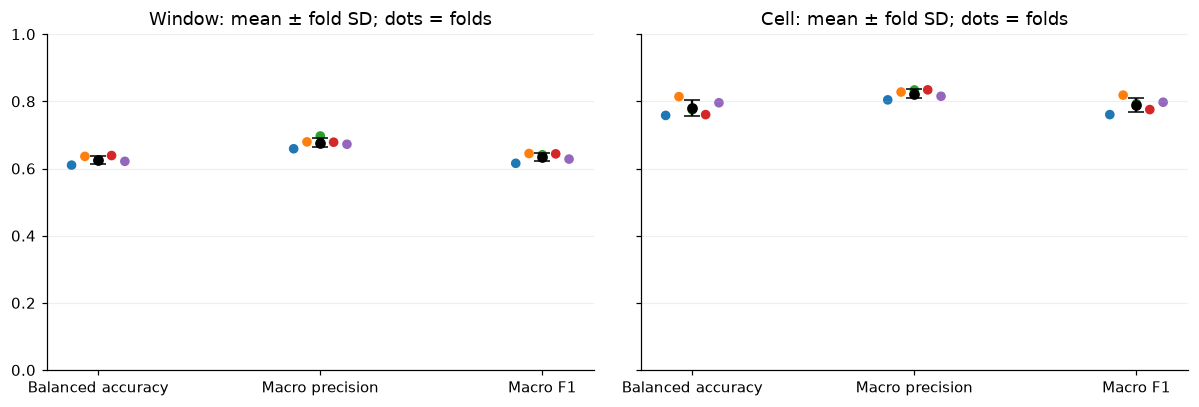

precision_mean  precision_fold_SD  recall_mean  \
Evaluation Class                                                             
Window     BasketFam                0.9564             0.0222       0.9693   
           BipFam                   0.8178             0.0601       0.7287   
           L2IT                     0.5431             0.0647       0.5054   
           L3IT                     0.4903             0.0846       0.3858   
           L4IT                     0.6851             0.0237       0.7476   
           L5ET                     0.7697             0.0899       0.6727   
           L5IT                     0.3802             0.0974       0.3847   
           L5NP                     0.3624             0.2632       0.0997   
           L6CT                     0.6311             0.0744       0.5637   
           L6IT                     0.4887             0.0791       0.5128   
           MartFam                  0.9273             0.0212       0.8890   
           NglFam                   0.8138             0.0517       0.7300   
           thalamocortical          0.9366             0.0110       0.9468   
Cell       BasketFam                0.9717             0.0282       0.9884   
           BipFam                   0.9100             0.0758       0.9470   
           L2IT                     0.8130             0.0552       0.8118   
           L3IT                     0.7421             0.0915       0.4876   
           L4IT                     0.7994             0.0612       0.9576   
           L5ET                     1.0000             0.0000       0.9036   
           L5IT                     0.8310             0.2159       0.6121   
           L5NP                     0.0000             0.0000       0.0000   
           L6CT                     0.9910             0.0123       0.8943   
           L6IT                     0.7575             0.0552       0.8285   
           MartFam                  0.9242             0.0351       0.8870   
           NglFam                   0.9600             0.0894       0.8300   
           thalamocortical          1.0000             0.0000       1.0000   

                            recall_fold_SD  true_count  predicted_count  \
Evaluation Class                                                          
Window     BasketFam                0.0074      528296           535997   
           BipFam                   0.0797       75615            68038   
           L2IT                     0.0976      108389           105327   
           L3IT                     0.0945      107316            87845   
           L4IT                     0.0500      290241           317229   
           L5ET                     0.0286       14006            12439   
           L5IT                     0.1441       72163            84315   
           L5NP                     0.0679        3804             3683   
           L6CT                     0.0604       33352            30242   
           L6IT                     0.0707       61258            65206   
           MartFam                  0.0251      357208           341919   
           NglFam                   0.0877       10689             9302   
           thalamocortical          0.0196       81873            82668   
Cell       BasketFam                0.0159         171              174   
           BipFam                   0.0573         113              118   
           L2IT                     0.1048         268              270   
           L3IT                     0.1502         219              147   
           L4IT                     0.0410         522              630   
           L5ET                     0.0957          51               46   
           L5IT                     0.2436         116              101   
           L5NP                     0.0000          10                2   
           L6CT                     0.0641         244              220   
           L6IT                     0.1074 

In [3]:
rows = []
for record in folds:
    rows.append({'Fold': record['fold'], 'Best epoch (0-based)': record['best_epoch'],
                 'Held-out windows': record['classified_windows'],
                 **{f'{unit} {metric}': record[key][metric]
                    for unit, key in [('Window', 'window_metrics'), ('Cell', 'cell_metrics')]
                    for metric in ['balanced_accuracy', 'macro_precision', 'macro_f1']}})
scores = pd.DataFrame(rows).set_index('Fold')
display(scores.round(4))
metric_columns = [c for c in scores if c.startswith(('Window ', 'Cell '))]
display(scores[metric_columns].agg(['mean', 'std']).T.rename(columns={'std': 'fold SD'}).round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, unit in zip(axes, ['Window', 'Cell']):
    for i, metric in enumerate(['balanced_accuracy', 'macro_precision', 'macro_f1']):
        values = scores[f'{unit} {metric}'].to_numpy()
        ax.errorbar(i, values.mean(), yerr=values.std(ddof=1), fmt='o', color='black', capsize=5)
        ax.scatter(i + np.linspace(-.12, .12, 5), values, c=COLORS[:5], s=28)
    ax.set_xticks(range(3), ['Balanced accuracy', 'Macro precision', 'Macro F1'])
    ax.set_title(f'{unit}: mean ± fold SD; dots = folds')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=.2)
fig.tight_layout()
plt.show()
leaf_precision = pd.concat({unit: class_precision_table(
    [record[key]['confusion_matrix'] for record in folds], leaf_names)
    for unit, key in [('Window', 'window_metrics'), ('Cell', 'cell_metrics')]},
    names=['Evaluation', 'Class'])
display(leaf_precision.round(4))
for record in folds:
    for key in ['window_metrics', 'cell_metrics']:
        actual = per_class_precision(np.asarray(record[key]['confusion_matrix']))
        np.testing.assert_allclose(actual, [record[key]['per_class_precision'][name] for name in leaf_names])

## Training curves

Curves include all 30 epochs; markers locate the selected checkpoint in
each fold. Validation here is the same cell-held-out fold reported above.

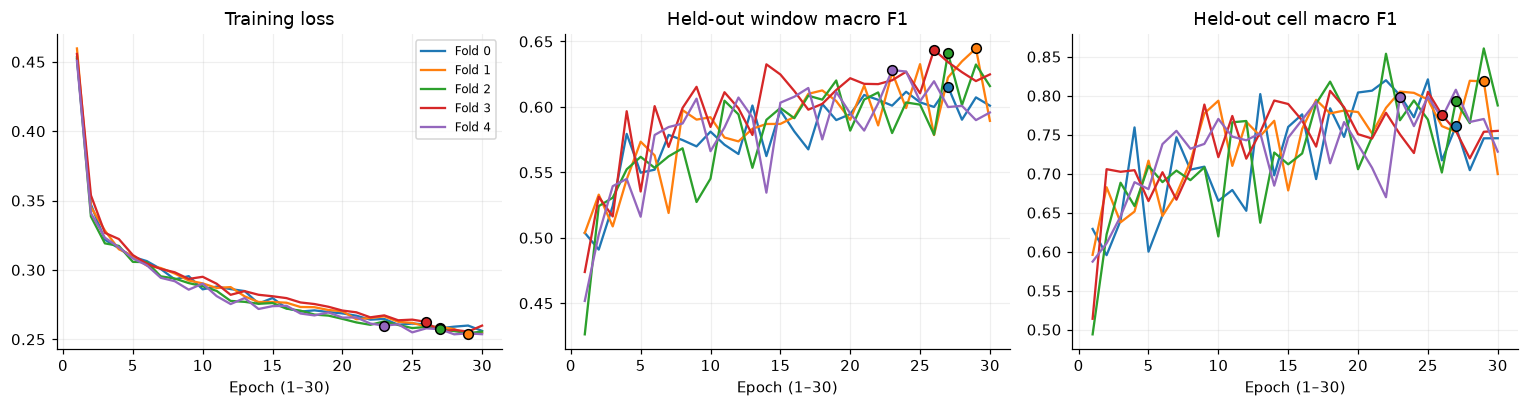

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for record in folds:
    frame = pd.read_csv(checkpoint_path(record).parent / 'epoch_metrics.csv')
    assert set(frame.epoch) == set(range(30))
    for ax, metric, title in zip(axes, ['train_loss', 'window_macro_f1', 'cell_macro_f1'],
                                 ['Training loss', 'Held-out window macro F1', 'Held-out cell macro F1']):
        ax.plot(frame.epoch + 1, frame[metric], color=COLORS[record['fold']], label=f"Fold {record['fold']}")
        best = frame.loc[frame.epoch == record['best_epoch']].iloc[-1]
        ax.scatter(best.epoch + 1, best[metric], color=COLORS[record['fold']], edgecolor='black', s=40, zorder=3)
        ax.set(title=title, xlabel='Epoch (1–30)')
        ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## End-to-end predictions at each hierarchy level

We collapse the saved **window-level leaf confusion matrices** to each
ancestor level. This measures the full predicted route, including upstream
errors. It is not conditional local-head performance. The constant neuron-only
root is omitted from the plot.
Per-class precision is reported separately for each level's class vocabulary.

balanced_accuracy         macro_precision         macro_f1  \
                           mean     std            mean     std     mean   
Level Classes                                                              
0     1                  1.0000  0.0000          1.0000  0.0000   1.0000   
1     2                  0.9778  0.0020          0.9759  0.0022   0.9767   
2     6                  0.8736  0.0213          0.9013  0.0071   0.8853   
3     9                  0.7290  0.0148          0.7940  0.0278   0.7450   
4     13                 0.6259  0.0117          0.6771  0.0137   0.6346   

                       
                  std  
Level Classes          
0     1        0.0000  
1     2        0.0021  
2     6        0.0150  
3     9        0.0120  
4     13       0.0126

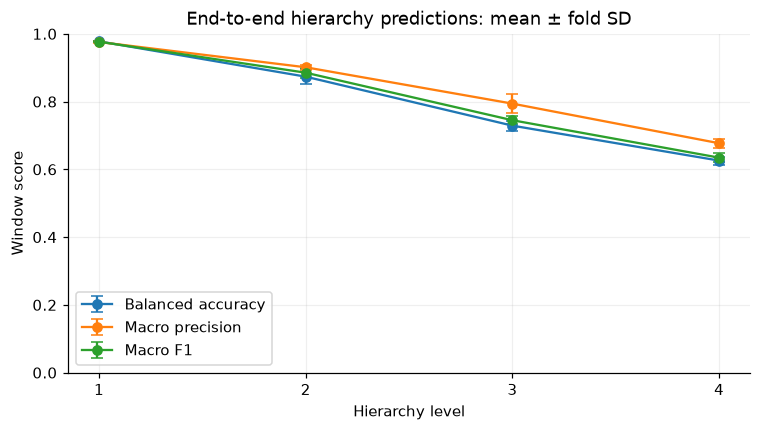

precision_mean  precision_fold_SD  recall_mean  \
Level Class                                                             
1     excitatory               0.9641             0.0078       0.9848   
      inhibitory               0.9877             0.0053       0.9708   
2     BasketFam                0.9564             0.0222       0.9693   
      BipFam                   0.8178             0.0601       0.7287   
      MartFam                  0.9273             0.0212       0.8890   
      NglFam                   0.8138             0.0517       0.7300   
      pyramidal                0.9559             0.0081       0.9775   
      thalamocortical          0.9366             0.0110       0.9468   
3     BasketFam                0.9564             0.0222       0.9693   
      BipFam                   0.8178             0.0601       0.7287   
      ET                       0.7697             0.0899       0.6727   
      IT                       0.9312             0.0062       0.9610   
      MartFam                  0.9273             0.0212       0.8890   
      NP                       0.3624             0.2632       0.0997   
      NglFam                   0.8138             0.0517       0.7300   
      corticothalamic          0.6311             0.0744       0.5637   
      thalamocortical          0.9366             0.0110       0.9468   
4     BasketFam                0.9564             0.0222       0.9693   
      BipFam                   0.8178             0.0601       0.7287   
      L2IT                     0.5431             0.0647       0.5054   
      L3IT                     0.4903             0.0846       0.3858   
      L4IT                     0.6851             0.0237       0.7476   
      L5ET                     0.7697             0.0899       0.6727   
      L5IT                     0.3802             0.0974       0.3847   
      L5NP                     0.3624             0.2632       0.0997   
      L6CT                     0.6311             0.0744       0.5637   
      L6IT                     0.4887             0.0791       0.5128   
      MartFam                  0.9273             0.0212       0.8890   
      NglFam                   0.8138             0.0517       0.7300   
      thalamocortical          0.9366             0.0110       0.9468   

                       recall_fold_SD  true_count  predicted_count  \
Level Class                                                          
1     excitatory               0.0066      772402           788954   
      inhibitory               0.0066      971808           955256   
2     BasketFam                0.0074      528296           535997   
      BipFam                   0.0797       75615            68038   
      MartFam                  0.0251      357208           341919   
      NglFam                   0.0877       10689             9302   
      pyramidal                0.0074      690529           706286   
      thalamocortical          0.0196       81873            82668   
3     BasketFam                0.0074      528296           535997   
      BipFam                   0.0797       75615            68038   
      ET                       0.0286       14006            12439   
      IT                       0.0106      639367           659922   
      MartFam                  0.0251      357208           341919   
      NP                       0.0679        3804             3683   
      NglFam                   0.0877       10689             9302   
      corticothalamic          0.0604       33352            30242   
      thalamocortical          0.0196       81873            82668   
4     BasketFam                0.0074      528296           535997   
      BipFam                   0.0797       75615            68038   
      L2IT                     0.0976      108389           105327   
      L3IT                     0.0945      107316            87845   
      L4IT                     0.0500      290241           317229   
      

In [5]:
def matrix_metrics(matrix):
    matrix = np.asarray(matrix)
    return {'balanced_accuracy': balanced_accuracy(matrix),
            'macro_precision': macro_precision(matrix), 'macro_f1': macro_f1(matrix)}
level_matrices = {}
level_rows = []
for record in folds:
    leaf = np.asarray(record['window_metrics']['confusion_matrix'])
    assert leaf.shape == (len(leaf_names), len(leaf_names))
    for level, names in enumerate(levels):
        ancestors = np.array([hierarchy.level_maps[level][hierarchy.label_paths[name][level]] for name in leaf_names])
        collapsed = np.zeros((len(names), len(names)), dtype=np.int64)
        np.add.at(collapsed, (ancestors[:, None], ancestors[None, :]), leaf)
        assert collapsed.sum() == record['classified_windows']
        level_matrices[(record['fold'], level)] = collapsed
        level_rows.append({'Fold': record['fold'], 'Level': level, 'Classes': len(names), **matrix_metrics(collapsed)})
    assert np.isclose(matrix_metrics(leaf)['macro_f1'], record['window_metrics']['macro_f1'])
level_scores = pd.DataFrame(level_rows)
display(level_scores.groupby(['Level', 'Classes'])[['balanced_accuracy', 'macro_precision', 'macro_f1']].agg(['mean', 'std']).round(4))
fig, ax = plt.subplots(figsize=(8, 4))
for metric, label in [('balanced_accuracy', 'Balanced accuracy'), ('macro_precision', 'Macro precision'), ('macro_f1', 'Macro F1')]:
    grouped = level_scores.query('Level > 0').groupby('Level')[metric].agg(['mean', 'std'])
    ax.errorbar(grouped.index, grouped['mean'], yerr=grouped['std'], marker='o', capsize=4, label=label)
ax.set(xticks=range(1, len(levels)), xlabel='Hierarchy level', ylabel='Window score', ylim=(0, 1),
       title='End-to-end hierarchy predictions: mean ± fold SD')
ax.legend()
ax.grid(alpha=.2)
plt.show()
level_precision = pd.concat({level: class_precision_table(
    [level_matrices[(fold, level)] for fold in range(5)], names)
    for level, names in enumerate(levels) if level > 0}, names=['Level', 'Class'])
display(level_precision.round(4))

## Every local head, conditioned on its true parent

A head is evaluated on windows whose true label lies under that parent,
regardless of upstream predictions. This separates local discrimination
from routing errors. Support counts sum across the disjoint held-out folds.
Precision here is conditional on the true parent, just like the head's
balanced accuracy; it is not end-to-end precision for that class.

,held_out_support,balanced_accuracy,balanced_accuracy_fold_SD,macro_precision,macro_precision_fold_SD,macro_F1,macro_F1_fold_SD
Parent,,,,,,,
neuron,1744210,0.9778,0.0020,0.9759,0.0022,0.9767,0.0021
excitatory,772402,0.9710,0.0107,0.9698,0.0038,0.9704,0.0068
inhibitory,971808,0.8588,0.0238,0.8749,0.0187,0.8645,0.0208
pyramidal,690529,0.5889,0.0155,0.7328,0.0661,0.6211,0.0159
IT,639367,0.5394,0.0214,0.5659,0.0230,0.5375,0.0174


precision_mean  precision_fold_SD  recall_mean  \
True parent Child class                                                       
neuron      excitatory               0.9641             0.0078       0.9848   
            inhibitory               0.9877             0.0053       0.9708   
excitatory  pyramidal                0.9940             0.0028       0.9936   
            thalamocortical          0.9456             0.0068       0.9484   
inhibitory  BasketFam                0.9586             0.0219       0.9720   
            BipFam                   0.7990             0.0565       0.8176   
            MartFam                  0.9318             0.0232       0.9113   
            NglFam                   0.8102             0.0648       0.7344   
pyramidal   ET                       0.8700             0.0659       0.7018   
            IT                       0.9690             0.0047       0.9813   
            NP                       0.4102             0.2842       0.1028   
            corticothalamic          0.6821             0.0626       0.5698   
IT          L2IT                     0.5733             0.0622       0.5155   
            L3IT                     0.5091             0.0864       0.3885   
            L4IT                     0.7129             0.0249       0.7612   
            L5IT                     0.4024             0.0886       0.3988   
            L6IT                     0.6319             0.0945       0.6331   

                             recall_fold_SD  true_count  predicted_count  \
True parent Child class                                                    
neuron      excitatory               0.0066      772402           788954   
            inhibitory               0.0065      971808           955256   
excitatory  pyramidal                0.0007      690529           690336   
            thalamocortical          0.0214       81873            82066   
inhibitory  BasketFam                0.0077      528296           536232   
            BipFam                   0.0660       75615            77202   
            MartFam                  0.0263      357208           348993   
            NglFam                   0.0888       10689             9381   
pyramidal   ET                       0.0306       14006            11395   
            IT                       0.0051      639367           647443   
            NP                       0.0697        3804             3542   
            corticothalamic          0.0567       33352            28149   
IT          L2IT                     0.0980      108389           101341   
            L3IT                     0.0956      107316            85122   
            L4IT                     0.0513      290241           310443   
            L5IT                     0.1509       72163            80624   
            L6IT                     0.1065       61258            61837   

                             folds_without_predictions  
True parent Child class                                 
neuron      excitatory                               0  
            inhibitory                               0  
excitatory  pyramidal                                0  
            thalamocortical                          0  
inhibitory  BasketFam                                0  
            BipFam                                   0  
            MartFam                                  0  
            NglFam                                   0  
pyramidal   ET                                       0  
            IT                                       0  
            NP                                       0  
            corticothalamic                          0  
IT          L2IT                                     0  
            L3IT                                     0  
            L4IT                                     0  
            L5IT                                     0  
            L6IT                                     0

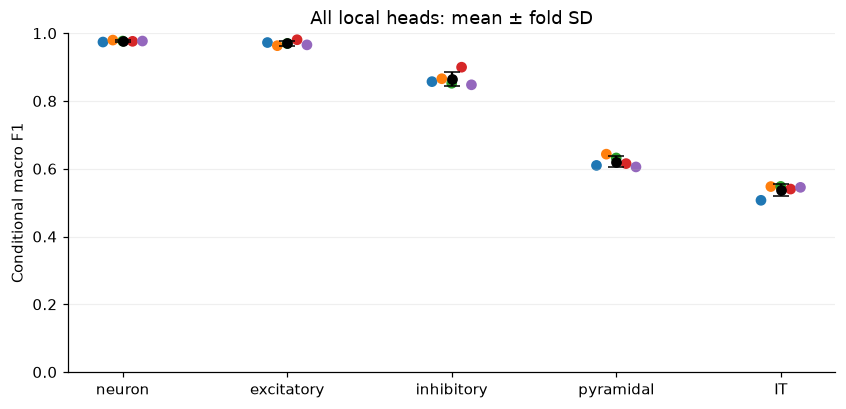

In [6]:
head_rows = []
head_matrices = {}
for record in folds:
    for i, metrics in enumerate(record['local_head_metrics']):
        assert metrics['parent'] == heads[i]['parent_name'] and metrics['children'] == heads[i]['children']
        matrix = np.asarray(metrics['confusion_matrix'])
        assert matrix.sum() == metrics['support']
        head_matrices[(record['fold'], i)] = matrix
        head_rows.append({'Fold': record['fold'], 'Head': i, 'Parent': metrics['parent'],
                          'Support': metrics['support'], **matrix_metrics(matrix)})
head_scores = pd.DataFrame(head_rows)
display(head_scores.groupby('Parent', sort=False).agg(
    held_out_support=('Support', 'sum'), balanced_accuracy=('balanced_accuracy', 'mean'),
    balanced_accuracy_fold_SD=('balanced_accuracy', 'std'),
    macro_precision=('macro_precision', 'mean'), macro_precision_fold_SD=('macro_precision', 'std'),
    macro_F1=('macro_f1', 'mean'), macro_F1_fold_SD=('macro_f1', 'std')).round(4))
head_precision = pd.concat({head['parent_name']: class_precision_table(
    [head_matrices[(fold, i)] for fold in range(5)], head['children'])
    for i, head in enumerate(heads)}, names=['True parent', 'Child class'])
display(head_precision.round(4))
fig, ax = plt.subplots(figsize=(9, 4))
for i, head in enumerate(heads):
    group = head_scores[head_scores.Head == i]
    values = group.macro_f1.to_numpy()
    ax.errorbar(i, values.mean(), yerr=values.std(ddof=1), fmt='o', color='black', capsize=5)
    ax.scatter(i + np.linspace(-.12, .12, 5), values, c=COLORS[:5])
ax.set(xticks=range(len(heads)), xticklabels=[h['parent_name'] for h in heads],
       ylabel='Conditional macro F1', ylim=(0, 1), title='All local heads: mean ± fold SD')
ax.grid(axis='y', alpha=.2)
plt.show()

## Confusion matrices and per-class precision

Rows are true classes and columns are predictions. Each fold is normalized
by its own row support **before** taking the equal-weight mean. Unsupported
rows are omitted from that row's mean rather than counted as zero recall.
These row-normalized matrices show recall; the precision panels below use
predicted-class counts as their denominator.

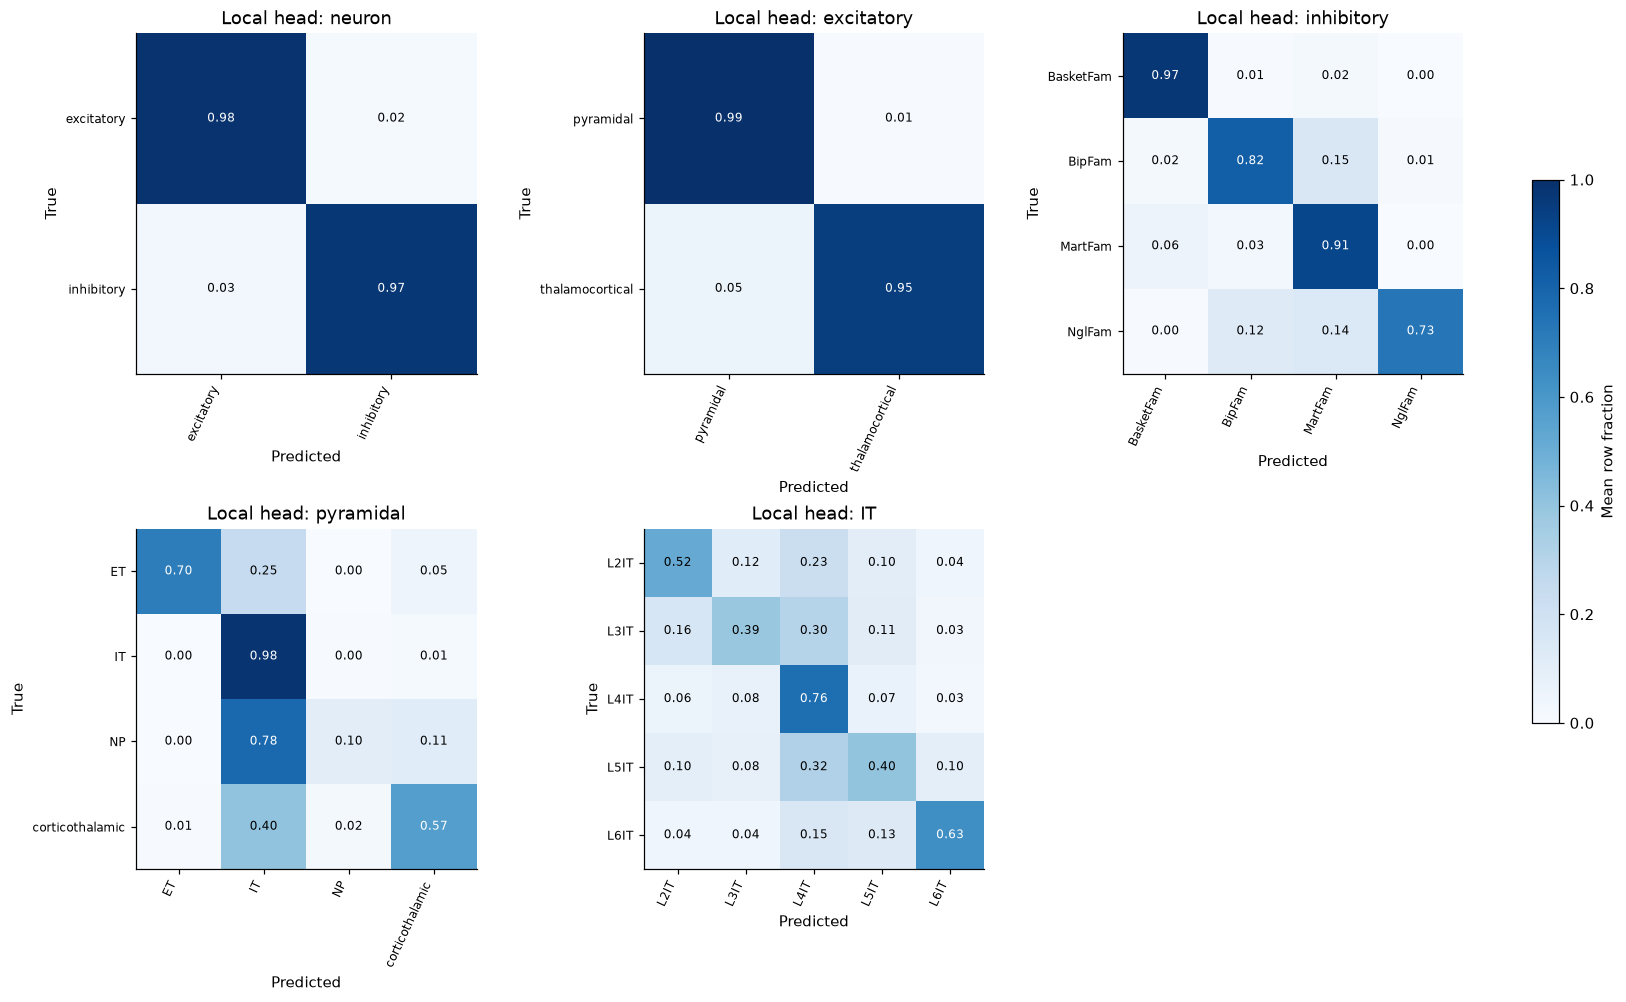

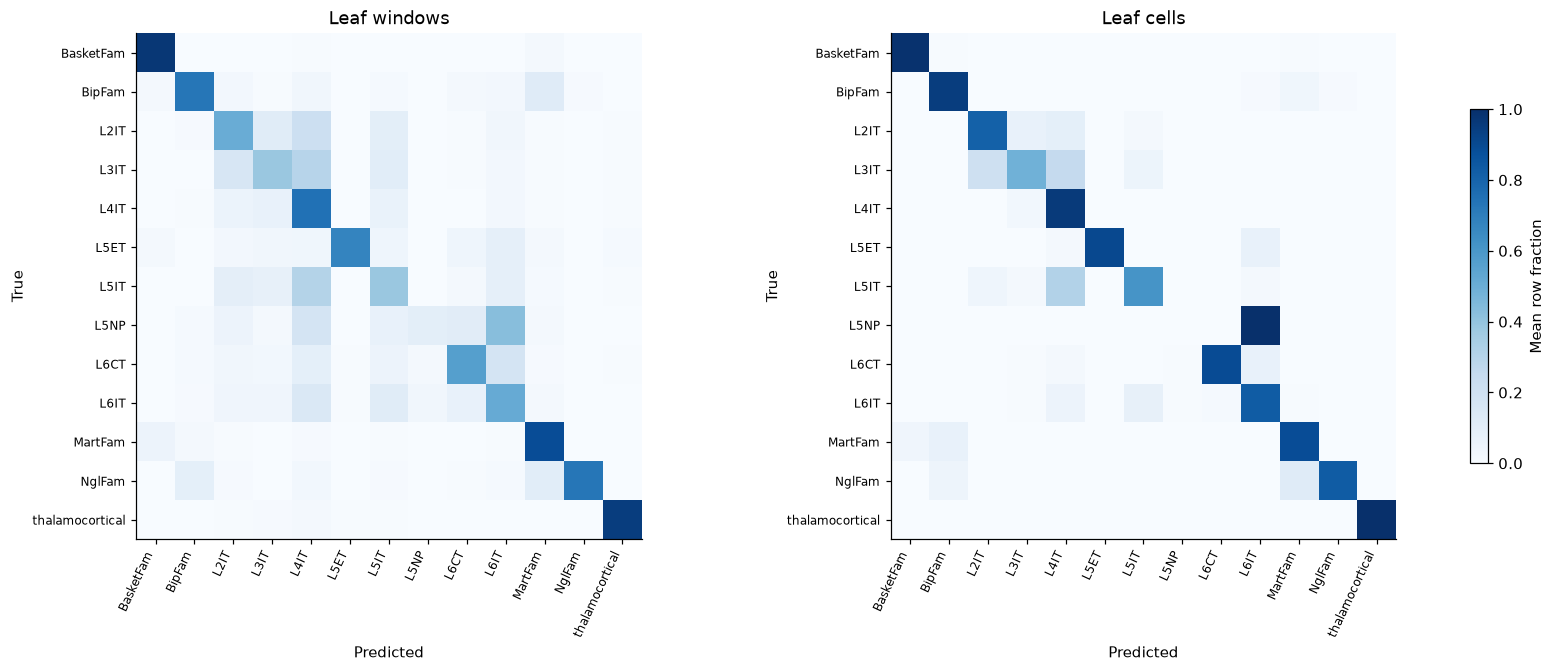

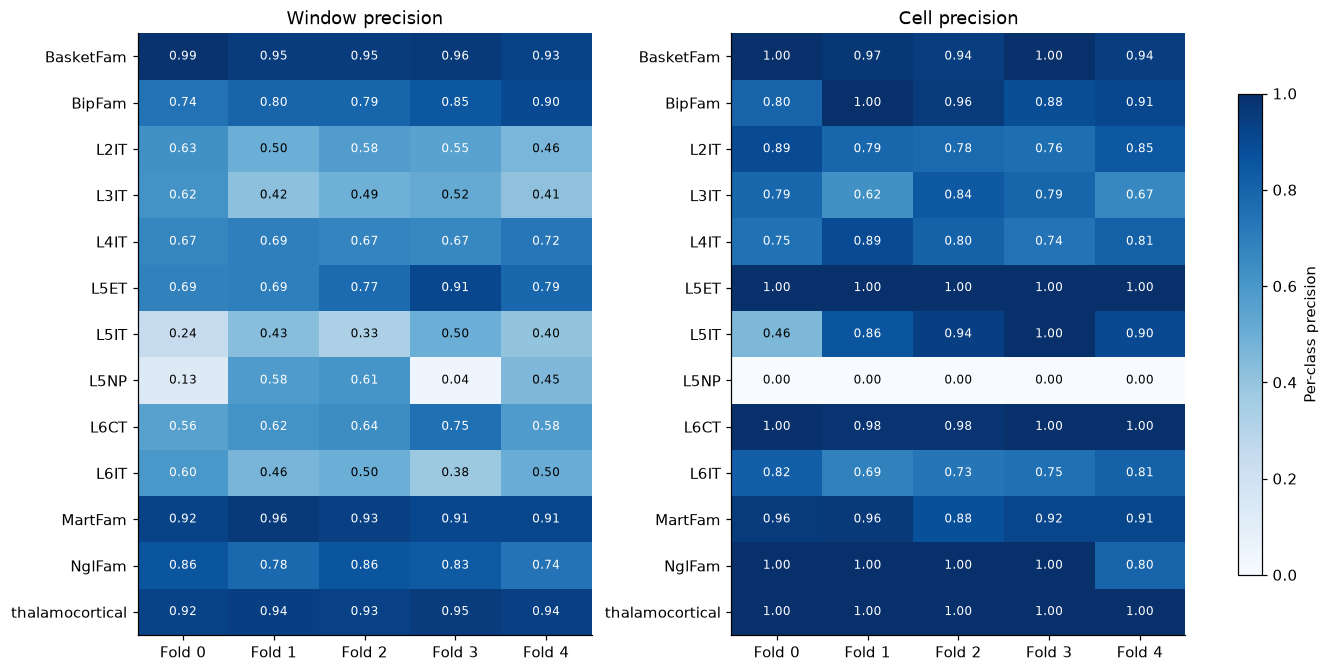

In [7]:
def mean_normalized(matrices):
    normalized = []
    for matrix in matrices:
        matrix = np.asarray(matrix, dtype=float)
        support = matrix.sum(1, keepdims=True)
        normalized.append(np.divide(matrix, support, out=np.full_like(matrix, np.nan), where=support > 0))
    return np.nanmean(normalized, axis=0)
def draw_matrix(ax, matrix, names, title, annotate=False):
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap='Blues')
    ax.set(xticks=range(len(names)), yticks=range(len(names)), xticklabels=names, yticklabels=names,
           xlabel='Predicted', ylabel='True', title=title)
    plt.setp(ax.get_xticklabels(), rotation=65, ha='right', fontsize=8)
    plt.setp(ax.get_yticklabels(), fontsize=8)
    if annotate:
        for (i, j), value in np.ndenumerate(matrix):
            if np.isfinite(value):
                ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8,
                        color='white' if value > .55 else 'black')
    return image
fig, axes = plt.subplots(2, 3, figsize=(15, 9), layout='constrained')
for i, head in enumerate(heads):
    matrix = mean_normalized([head_matrices[(f, i)] for f in range(5)])
    image = draw_matrix(axes.flat[i], matrix, head['children'], f"Local head: {head['parent_name']}", True)
axes.flat[-1].axis('off')
fig.colorbar(image, ax=list(axes.flat[:-1]), shrink=.65, label='Mean row fraction')
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout='constrained')
for ax, key, title in zip(axes, ['window_metrics', 'cell_metrics'], ['Leaf windows', 'Leaf cells']):
    matrix = mean_normalized([record[key]['confusion_matrix'] for record in folds])
    image = draw_matrix(ax, matrix, leaf_names, title)
fig.colorbar(image, ax=axes.tolist(), shrink=.7, label='Mean row fraction')
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 6), layout='constrained')
for ax, key, title in zip(axes, ['window_metrics', 'cell_metrics'], ['Window precision', 'Cell precision']):
    precision = pd.DataFrame({f"Fold {r['fold']}": r[key]['per_class_precision'] for r in folds}).reindex(leaf_names)
    image = ax.imshow(precision.to_numpy(), vmin=0, vmax=1, cmap='Blues', aspect='auto')
    ax.set(xticks=range(5), xticklabels=precision.columns, yticks=range(len(leaf_names)),
           yticklabels=leaf_names, title=title)
    for (i, j), value in np.ndenumerate(precision.to_numpy()):
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8,
                color='white' if value > .55 else 'black')
fig.colorbar(image, ax=axes.tolist(), shrink=.8, label='Per-class precision')
plt.show()

## Number of embeddings per window

This reads only the `n_embeddings` column, in batches, from the saved
predictions. Counts describe eligible, deduplicated held-out windows rather
than every raw synapse. The ten-embedding line is a reference to the previous
selection rule, not a matched model-performance comparison.

,Value
Mean embeddings,21.638481
10th percentile,14.000000
Median,22.000000
90th percentile,29.000000
Maximum,97.000000
Fraction below 10,0.013602


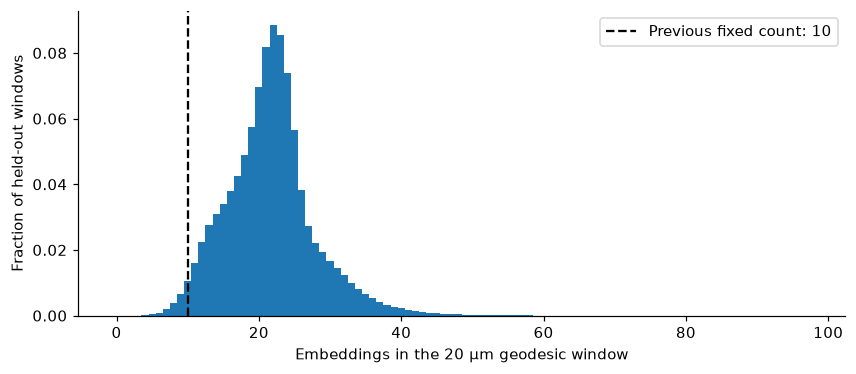

In [8]:
size_counts = {}
for record in folds:
    histogram = np.zeros(plan['maximum_embeddings'] + 1, np.int64)
    for batch in pq.ParquetFile(predictions_path(record['fold'])).iter_batches(columns=['n_embeddings'], batch_size=65536):
        sizes = batch.column(0).to_numpy()
        assert (sizes > 0).all() and sizes.max() <= plan['maximum_embeddings']
        histogram += np.bincount(sizes, minlength=len(histogram))
    assert histogram.sum() == record['classified_windows']
    size_counts[record['fold']] = histogram
counts = sum(size_counts.values())
x = np.arange(len(counts))
quantiles = x[np.searchsorted(np.cumsum(counts), np.array([.1, .5, .9]) * counts.sum())]
display(pd.Series({'Mean embeddings': np.dot(x, counts) / counts.sum(),
                   '10th percentile': quantiles[0], 'Median': quantiles[1],
                   '90th percentile': quantiles[2], 'Maximum': x[counts > 0].max(),
                   'Fraction below 10': counts[:10].sum() / counts.sum()}).to_frame('Value'))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x, counts / counts.sum(), width=1, color=COLORS[0])
ax.axvline(10, color='black', linestyle='--', label='Previous fixed count: 10')
ax.set(xlabel='Embeddings in the 20 µm geodesic window', ylabel='Fraction of held-out windows')
ax.legend()
plt.show()

## Inspect saved logits from every head

Edit `FOLD`, `N_ROWS` and `ROW` below. The preview takes the first rows for
inspection, **not a representative random sample**. Logits are local raw
scores; the associated softmax probabilities are conditional on the head's
parent. Do not softmax logits from different heads together. Joint
probabilities multiply the relevant probabilities along the hierarchy.
An off-path head still has logits, but its conditional decision is not a
claim that the window belongs to that parent.

In [9]:
FOLD = 0
N_ROWS = 8
ROW = 0
assert 0 <= FOLD < 5 and 0 <= ROW < N_ROWS
sample = next(pq.ParquetFile(predictions_path(FOLD)).iter_batches(batch_size=N_ROWS)).to_pandas()
preview = sample[['root_id', 'synapse_id', 'window_row', 'n_embeddings']].copy()
preview['true_leaf'] = [manifests[FOLD]['cells'][str(int(rid))]['cell_type'] for rid in sample.root_id]
preview['predicted_leaf'] = [leaf_names[int(path[-1])] for path in sample.top_down_predictions]
display(preview)
row = sample.iloc[ROW]
truth = hierarchy.label_paths[preview.iloc[ROW].true_leaf]
local_rows = []
for i, head in enumerate(heads):
    logits = np.asarray(row[f'head_{i}_logits'])
    probabilities = np.asarray(row[f'head_{i}_probabilities'])
    assert len(logits) == head['n_children'] and np.isclose(probabilities.sum(), 1, atol=1e-6)
    on_path = head['parent_level'] < 0 or truth[head['parent_level']] == head['parent_name']
    for child, logit, probability in zip(head['children'], logits, probabilities):
        local_rows.append({'Head parent': head['parent_name'], 'On true parent path': on_path,
                           'Child': child, 'Logit': float(logit), 'Conditional probability': float(probability)})
display(pd.DataFrame(local_rows).set_index(['Head parent', 'Child']).round(5))
joint_rows = []
for level, names in enumerate(levels):
    probabilities = np.asarray(row[f'level_{level}_joint_probabilities'])
    assert np.isclose(probabilities.sum(), 1, atol=1e-5)
    selected = int(row.top_down_predictions[level])
    for i, (name, probability) in enumerate(zip(names, probabilities)):
        joint_rows.append({'Level': level, 'Class': name, 'Joint probability': float(probability),
                           'Top-down selection': i == selected})
display(pd.DataFrame(joint_rows).set_index(['Level', 'Class']).round(5))

,root_id,synapse_id,window_row,n_embeddings,true_leaf,predicted_leaf
0,864691134887444986,170338832,0,22,NglFam,BipFam
1,864691134887444986,185839131,1,37,NglFam,NglFam
2,864691134887444986,233361721,2,30,NglFam,NglFam
3,864691134887444986,171354532,3,37,NglFam,NglFam
4,864691134887444986,185511685,5,15,NglFam,NglFam
5,864691134887444986,202647217,6,14,NglFam,NglFam
6,864691134887444986,157533101,7,31,NglFam,NglFam
7,864691134887444986,160833627,8,30,NglFam,NglFam


On true parent path    Logit  \
Head parent Child                                           
neuron      excitatory                      True -1.95920   
            inhibitory                      True  2.45995   
excitatory  pyramidal                      False  1.68509   
            thalamocortical                False -1.35110   
inhibitory  BasketFam                       True -2.83493   
            BipFam                          True  2.75911   
            MartFam                         True -1.80062   
            NglFam                          True  0.46805   
pyramidal   ET                             False -2.80785   
            IT                             False  1.91085   
            NP                             False -2.69572   
            corticothalamic                False -1.39424   
IT          L2IT                           False  1.25408   
            L3IT                           False  1.06682   
            L4IT                           False  1.17998   
            L5IT                           False -0.63265   
            L6IT                           False -2.16243   

                             Conditional probability  
Head parent Child                                     
neuron      excitatory                       0.01190  
            inhibitory                       0.98810  
excitatory  pyramidal                        0.95418  
            thalamocortical                  0.04582  
inhibitory  BasketFam                        0.00334  
            BipFam                           0.89658  
            MartFam                          0.00938  
            NglFam                           0.09070  
pyramidal   ET                               0.00846  
            IT                               0.94732  
            NP                               0.00946  
            corticothalamic                  0.03476  
IT          L2IT                             0.33988  
            L3IT                             0.28184  
            L4IT                             0.31561  
            L5IT                             0.05151  
            L6IT                             0.01116

Joint probability  Top-down selection
Level Class                                                 
0     neuron                     1.00000                True
1     excitatory                 0.01190               False
      inhibitory                 0.98810                True
2     BasketFam                  0.00330               False
      BipFam                     0.88591                True
      MartFam                    0.00927               False
      NglFam                     0.08962               False
      pyramidal                  0.01136               False
      thalamocortical            0.00055               False
3     BasketFam                  0.00330               False
      BipFam                     0.88591                True
      ET                         0.00010               False
      IT                         0.01076               False
      MartFam                    0.00927               False
      NP                         0.00011               False
      NglFam                     0.08962               False
      corticothalamic            0.00039               False
      thalamocortical            0.00055               False
4     BasketFam                  0.00330               False
      BipFam                     0.88591                True
      L2IT                       0.00366               False
      L3IT                       0.00303               False
      L4IT                       0.00340               False
      L5ET                       0.00010               False
      L5IT                       0.00055               False
      L5NP                       0.00011               False
      L6CT                       0.00039               False
      L6IT                       0.00012               False
      MartFam                    0.00927               False
      NglFam                     0.08962               False
      thalamocortical            0.00055               False

## Files and provenance

`completion.json` records verified checkpoint hashes and coverage.
`all_lcpn_predictions/fold*.json` records head ordering, score semantics and
Parquet hashes. Source anchor eligibility was preserved per site, including
historical 2 µm/5 µm differences documented in `source_anchor_audit.json`.
Source soma geometry, folds and newest 100k SegCLR features were retained:
the 5 µm cut applies where present; explicitly soma-free records retain their
full skeleton. The finer hierarchy changes the label task from the earlier
six-class run, so its leaf scores should not be compared directly to that run.

See [the experiment and upstream pipeline notes](../../../docs/presynaptic_geodesic20um.md).

In [10]:
display(pd.DataFrame([{'Fold': r['fold'], 'Checkpoint': str(checkpoint_path(r)),
                       'Predictions': str(predictions_path(r['fold'])),
                       'Rows': r['classified_windows']} for r in folds]).set_index('Fold'))
display(pd.Series({'Embedding run': plan['feature_run_id'],
                   'SegCLR checkpoint SHA256': plan['feature_checkpoint_sha256'],
                   'Anchor policy': plan['anchor_match_policy'],
                   'Completion plan SHA256': completion['plan_sha256']}).to_frame('Provenance'))

,Checkpoint,Predictions,Rows
Fold,,,
0,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,344139
1,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,355831
2,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,342105
3,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,349411
4,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,352724


,Provenance
Embedding run,resnet50_1280b_slab1280_50um_mac_partial_aug_2_style_bf16_100k__20261022_140504
SegCLR checkpoint SHA256,826eebf68fdd47e979385c8f401825a8c9f4f2ea2c838794066f5b906a080897
Anchor policy,preserve per-site cave_within_match_cutoff; source records include 2um and 5...
Completion plan SHA256,a80f0ef007370c0b2cfcccb1f2b3119a667a15843cf972a719ed7ae2055709d8


## segclr-db export

The receipt below records the verified export of these held-out windows,
with one prediction run per fold and raw logits from all five local heads.
Database `root_id` is the postsynaptic target; `subject_root_id` is the
classified presynaptic cell. Node IDs refer to its canonical CAVE skeleton.

Database logits are stored in hierarchy-level class order. Apply softmax
separately over each head's `child_global_indices`, never over a whole level.
Full conditional and joint probabilities remain in the shared artifact
bundle's `all_lcpn_predictions/fold*.parquet` files. The export does not run
inference on additional synapses or integrate the production predictor.

In [11]:
receipt_path = RUN / 'segclr_db_export/receipt.json'
if receipt_path.exists():
    export = json.loads(receipt_path.read_text())
    assert export['complete'] and len(export['folds']) == 5
    display(pd.Series({key: export[key] for key in
                       ('database_root', 'dataset', 'shared_bundle', 'predictions',
                        'level_logit_rows', 'completed_utc')}).to_frame('Verified export'))
    display(pd.DataFrame(export['folds']).set_index('fold'))
else:
    print('No completed segclr-db export receipt is present.')

,Verified export
database_root,/orcd/compute/sdorkenw/001/segclr-db
dataset,microns
shared_bundle,/orcd/compute/sdorkenw/001/jcbliao/segclr_workflows/latest100k_geodesic20um_...
predictions,1744210
level_logit_rows,8721050
completed_utc,2026-10-26T15:59:50.853620+00:00


,prediction_run_id,predictions,level_logit_rows,exact_roundtrip_verified
fold,,,,
0,presynaptic_geo20um_full_lcpn_fold0_a80f0ef00737__20261026_154159.checkpoint...,344139,1720695,True
1,presynaptic_geo20um_full_lcpn_fold1_a80f0ef00737__20261026_154159.checkpoint...,355831,1779155,True
2,presynaptic_geo20um_full_lcpn_fold2_a80f0ef00737__20261026_154159.checkpoint...,342105,1710525,True
3,presynaptic_geo20um_full_lcpn_fold3_a80f0ef00737__20261026_154159.checkpoint...,349411,1747055,True
4,presynaptic_geo20um_full_lcpn_fold4_a80f0ef00737__20261026_154159.checkpoint...,352724,1763620,True
